In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/competitions/multiple-object-video-detection-hw-2-ucu-ai-2026/test_images.csv
/kaggle/input/competitions/multiple-object-video-detection-hw-2-ucu-ai-2026/val/annotations_coco.json
/kaggle/input/competitions/multiple-object-video-detection-hw-2-ucu-ai-2026/val/data.yaml
/kaggle/input/competitions/multiple-object-video-detection-hw-2-ucu-ai-2026/val/labels/uav0000117_02622_v/0000141.txt
/kaggle/input/competitions/multiple-object-video-detection-hw-2-ucu-ai-2026/val/labels/uav0000117_02622_v/0000065.txt
/kaggle/input/competitions/multiple-object-video-detection-hw-2-ucu-ai-2026/val/labels/uav0000117_02622_v/0000313.txt
/kaggle/input/competitions/multiple-object-video-detection-hw-2-ucu-ai-2026/val/labels/uav0000117_02622_v/0000215.txt
/kaggle/input/competitions/multiple-object-video-detection-hw-2-ucu-ai-2026/val/labels/uav0000117_02622_v/0000171.txt
/kaggle/input/competitions/multiple-object-video-detection-hw-2-ucu-ai-2026/val/labels/uav0000117_02622_v/0000052.txt
/kaggle/

In [2]:
from pathlib import Path

INPUT_DIR = Path("/kaggle/input")

for dataset_dir in sorted(INPUT_DIR.iterdir()):
    print(f"\nDataset: {dataset_dir}")
    if dataset_dir.is_dir():
        for item in sorted(dataset_dir.iterdir()):
            print(f"  {item.name}{'/' if item.is_dir() else ''}")


Dataset: /kaggle/input/competitions
  multiple-object-video-detection-hw-2-ucu-ai-2026/


In [3]:
DATA_ROOT = (
    INPUT_DIR
    / "competitions"
    / "multiple-object-video-detection-hw-2-ucu-ai-2026"
)

assert DATA_ROOT.is_dir(), f"Dataset directory not found: {DATA_ROOT}"

for item in sorted(DATA_ROOT.iterdir()):
    print(f"{item.name}{'/' if item.is_dir() else ''}")

test/
test_images.csv
train/
val/


In [4]:
import json

annotations = {}

for split in ("train", "val"):
    split_dir = DATA_ROOT / split
    print(f"\n{split.upper()}:")

    for item in sorted(split_dir.iterdir()):
        print(f"  {item.name}{'/' if item.is_dir() else ''}")

    annotation_path = split_dir / "annotations_coco.json"
    assert annotation_path.is_file(), f"Missing: {annotation_path}"

    with annotation_path.open(encoding="utf-8") as f:
        annotations[split] = json.load(f)

    coco = annotations[split]

    print(f"Images: {len(coco['images']):,}")
    print(f"Annotations (including ignored): {len(coco['annotations']):,}")
    print("Categories:", coco["categories"])
    print("Example image:", coco["images"][0])
    print("Example annotation:", coco["annotations"][0])


TRAIN:
  annotations_coco.json
  data.yaml
  ignore/
  images/
  labels/
Images: 24,201
Annotations (including ignored): 1,616,260
Categories: [{'id': 1, 'name': 'person'}, {'id': 2, 'name': 'bicycle'}, {'id': 3, 'name': 'car'}, {'id': 4, 'name': 'van'}, {'id': 5, 'name': 'truck'}, {'id': 6, 'name': 'tricycle'}, {'id': 7, 'name': 'bus'}, {'id': 8, 'name': 'motor'}]
Example image: {'id': 1, 'file_name': 'images/uav0000013_00000_v/0000001.jpg', 'width': 1344, 'height': 756, 'video_id': 1, 'video': 'uav0000013_00000_v', 'frame_id': 1}
Example annotation: {'id': 1, 'image_id': 1, 'category_id': 1, 'bbox': [424, 543, 35, 88], 'area': 3080, 'iscrowd': 0, 'truncation': 0, 'occlusion': 0, 'track_id': 2, 'orig_category_id': 1}

VAL:
  annotations_coco.json
  data.yaml
  ignore/
  images/
  labels/
Images: 2,846
Annotations (including ignored): 146,092
Categories: [{'id': 1, 'name': 'person'}, {'id': 2, 'name': 'bicycle'}, {'id': 3, 'name': 'car'}, {'id': 4, 'name': 'van'}, {'id': 5, 'name': 't

In [5]:
import pandas as pd

summary_rows = []
videos_by_split = {}

for split, coco in annotations.items():
    videos = {img["video"] for img in coco["images"]}
    videos_by_split[split] = videos

    n_ignored = sum(
        ann.get("iscrowd", 0) == 1
        for ann in coco["annotations"]
    )
    n_objects = len(coco["annotations"]) - n_ignored
    n_images = len(coco["images"])

    summary_rows.append({
        "split": split,
        "clips": len(videos),
        "frames": n_images,
        "objects": n_objects,
        "ignored_regions": n_ignored,
        "objects_per_frame": round(n_objects / n_images, 2),
    })

summary = pd.DataFrame(summary_rows)
display(summary)

shared_videos = videos_by_split["train"] & videos_by_split["val"]
print("Shared train/val clips:", sorted(shared_videos))

assert not shared_videos, "Train/val contain overlapping video names!"

,split,clips,frames,objects,ignored_regions,objects_per_frame
0,train,56,24201,1105516,510744,45.68
1,val,7,2846,114132,31960,40.10


Shared train/val clips: []


### Dataset Structure and Split Verification

We verified that the training set contains 56 video clips
and 24,201 frames, while the validation set contains 7 clips
and 2,846 frames. We found no overlapping video names
between the two splits.

After excluding ignored regions, we counted 1,105,516 target
objects in the training set and 114,132 in the validation set.
On average, we have 45.68 objects per training frame and
40.10 per validation frame. Next, we will examine the
distribution of object counts and differences across clips.

We count ignored regions separately and exclude them from
target-object statistics. During training, we will account
for these regions rather than treating them as ordinary background.

In [6]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.colors import LinearSegmentedColormap

SEED = 42
rng = np.random.default_rng(SEED)

SPLIT_COLORS = {
    "train": "#8B5CF6", # purple
    "val": "#EC4899", # pink
}

CLASS_COLORS = [
    "#6D28D9", "#8B5CF6", "#A78BFA", "#C4B5FD",
    "#BE185D", "#DB2777", "#EC4899", "#F9A8D4",
]

PURPLE_PINK_CMAP = LinearSegmentedColormap.from_list(
    "purple_pink",
    ["#FAF5FF", "#C4B5FD", "#8B5CF6", "#DB2777"],
)

sns.set_theme(
    style="whitegrid",
    context="notebook",
    rc={
        "figure.figsize": (11, 4.5),
        "figure.dpi": 120,
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.titleweight": "bold",
        "axes.titlepad": 14,
        "grid.color": "#EDE4F3",
        "grid.alpha": 0.7,
        "axes.edgecolor": "#D8CBE3",
    },
)

sns.set_palette(CLASS_COLORS)

### Preparing Tables for Exploratory Analysis

We organize the annotations into frame-level and object-level
tables. We keep the split and video name for each frame so that
we can compare classes, object sizes, and scene density across clips.

We exclude ignored regions from the target-object table and count
them separately for each frame. We retain frames without target
objects to avoid biasing our scene-density statistics.

In [7]:
def build_eda_tables(coco, split):
    frames = pd.DataFrame.from_records(
        coco["images"],
        columns=["id", "file_name", "width", "height", "video", "frame_id"],
    ).rename(columns={"id": "image_id"})

    assert frames["image_id"].is_unique
    frames["split"] = split

    # Extract only the fields needed for EDA.
    ann = pd.DataFrame.from_records(
        coco["annotations"],
        columns=["image_id", "category_id", "bbox", "iscrowd"],
    )

    ignored = ann["iscrowd"].eq(1)
    objects = ann.loc[
        ~ignored, ["image_id", "category_id", "bbox"]
    ].copy()

    category_names = {
        category["id"]: category["name"]
        for category in coco["categories"]
    }

    assert objects["category_id"].isin(category_names).all()
    assert ann["image_id"].isin(frames["image_id"]).all()

    boxes = np.asarray(objects.pop("bbox").tolist(), dtype=np.float32)
    objects[["x", "y", "box_width", "box_height"]] = boxes.reshape(-1, 4)

    objects["class_id"] = objects.pop("category_id").astype("int8") - 1
    objects["class_name"] = objects["class_id"].add(1).map(category_names)

    objects = objects.merge(
        frames[["image_id", "split", "video", "width", "height"]],
        on="image_id",
        how="left",
        validate="many_to_one",
    )

    objects["box_area"] = objects["box_width"] * objects["box_height"]
    objects["relative_area"] = (
        objects["box_area"] / (objects["width"] * objects["height"])
    )

    frames["n_objects"] = (
        frames["image_id"]
        .map(objects["image_id"].value_counts())
        .fillna(0)
        .astype("int32")
    )
    frames["n_ignored"] = (
        frames["image_id"]
        .map(ann.loc[ignored, "image_id"].value_counts())
        .fillna(0)
        .astype("int32")
    )

    return frames, objects


eda_tables = {
    split: build_eda_tables(coco, split)
    for split, coco in annotations.items()
}

frames_df = pd.concat(
    [tables[0] for tables in eda_tables.values()],
    ignore_index=True,
)
objects_df = pd.concat(
    [tables[1] for tables in eda_tables.values()],
    ignore_index=True,
)

for column in ["split", "video"]:
    frames_df[column] = frames_df[column].astype("category")
    objects_df[column] = objects_df[column].astype("category")

objects_df["class_name"] = objects_df["class_name"].astype("category")

del eda_tables

print(f"Frames:  {len(frames_df):,}")
print(f"Objects: {len(objects_df):,}")

display(objects_df.head())

display(
    frames_df.groupby("split", observed=True).agg(
        frames=("image_id", "size"),
        objects=("n_objects", "sum"),
        ignored_regions=("n_ignored", "sum"),
        empty_frames=("n_objects", lambda counts: counts.eq(0).sum()),
    )
)

Frames:  27,047
Objects: 1,219,648


,image_id,x,y,box_width,box_height,class_id,class_name,split,video,width,height,box_area,relative_area
0,1,424.0,543.0,35.0,88.0,0,person,train,uav0000013_00000_v,1344,756,3080.0,0.003031
1,1,416.0,530.0,36.0,85.0,0,person,train,uav0000013_00000_v,1344,756,3060.0,0.003012
2,1,531.0,641.0,87.0,114.0,5,tricycle,train,uav0000013_00000_v,1344,756,9918.0,0.009761
3,1,591.0,422.0,32.0,79.0,0,person,train,uav0000013_00000_v,1344,756,2528.0,0.002488
4,1,454.0,413.0,21.0,48.0,0,person,train,uav0000013_00000_v,1344,756,1008.0,0.000992


,frames,objects,ignored_regions,empty_frames
split,,,,
train,24201,1105516,510744,3
val,2846,114132,31960,0


### Class Distribution

We examine the number of annotations for each target class and
compare class proportions between the training and validation sets.
We exclude ignored regions from this analysis.

We report both counts and percentages because the two splits differ
in size. These counts represent object appearances across frames,
not unique tracked objects.

,train_count,val_count,train_%,val_%,val_minus_train_pp
class_name,,,,,
person,"328,701","50,312",29.73,44.08,+14.35
bicycle,"40,255","6,022",3.64,5.28,+1.64
car,"505,301","31,821",45.71,27.88,-17.83
van,"46,940","6,842",4.25,5.99,+1.75
truck,"30,498","1,359",2.76,1.19,-1.57
tricycle,"41,349","5,487",3.74,4.81,+1.07
bus,"9,653",264,0.87,0.23,-0.64
motor,"102,819","12,025",9.30,10.54,+1.24


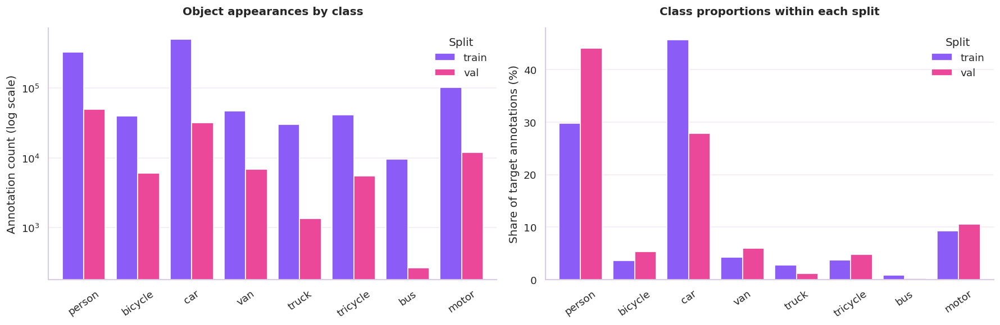

In [8]:
CLASS_NAMES = [
    "person", "bicycle", "car", "van",
    "truck", "tricycle", "bus", "motor",
]

class_counts = pd.crosstab(
    objects_df["class_name"],
    objects_df["split"],
).reindex(
    index=CLASS_NAMES,
    columns=["train", "val"],
    fill_value=0,
)

class_shares = class_counts.div(class_counts.sum(axis=0), axis=1) * 100

class_summary = pd.DataFrame({
    "train_count": class_counts["train"],
    "val_count": class_counts["val"],
    "train_%": class_shares["train"],
    "val_%": class_shares["val"],
    "val_minus_train_pp": class_shares["val"] - class_shares["train"],
})

display(
    class_summary.style
    .format({
        "train_count": "{:,.0f}",
        "val_count": "{:,.0f}",
        "train_%": "{:.2f}",
        "val_%": "{:.2f}",
        "val_minus_train_pp": "{:+.2f}",
    })
    .background_gradient(
        subset=["train_%", "val_%"],
        cmap=PURPLE_PINK_CMAP,
        axis=None,
    )
)

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

class_counts.plot.bar(
    ax=axes[0],
    color=[SPLIT_COLORS["train"], SPLIT_COLORS["val"]],
    width=0.8,
)
axes[0].set_yscale("log")
axes[0].set_title("Object appearances by class")
axes[0].set_ylabel("Annotation count (log scale)")

class_shares.plot.bar(
    ax=axes[1],
    color=[SPLIT_COLORS["train"], SPLIT_COLORS["val"]],
    width=0.8,
)
axes[1].set_title("Class proportions within each split")
axes[1].set_ylabel("Share of target annotations (%)")

for ax in axes:
    ax.set_xlabel("")
    ax.tick_params(axis="x", rotation=35)
    ax.grid(axis="x", visible=False)
    ax.legend(title="Split", frameon=False)

plt.tight_layout()
plt.show()

### Class Distribution: Findings

We observe a strong class imbalance in the training set.
Cars account for 45.71% of target annotations and people for
29.73%, together representing approximately 75.44% of the total.

We also observe different class proportions across the splits.
People are more common in validation (44.08% versus 29.73%),
while cars are less common (27.88% versus 45.71%).

Buses are the least represented class, with 9,653 training
annotations and 264 validation annotations. Since these are
appearances across video frames, they do not represent the
same number of unique objects or independent examples.

We will examine class coverage across clips and report per-class
AP alongside aggregate metrics. We will treat class balancing
as an experimental choice and evaluate its effect rather than
assuming that it improves detection.

In [9]:
box_columns = ["x", "y", "box_width", "box_height"]
box_values = objects_df[box_columns].to_numpy()

finite = np.isfinite(box_values).all(axis=1)
positive_size = (
    objects_df["box_width"].gt(0)
    & objects_df["box_height"].gt(0)
)

tolerance = 1e-3
outside_image = (
    objects_df["x"].lt(-tolerance)
    | objects_df["y"].lt(-tolerance)
    | (
        objects_df["x"] + objects_df["box_width"]
        > objects_df["width"] + tolerance
    )
    | (
        objects_df["y"] + objects_df["box_height"]
        > objects_df["height"] + tolerance
    )
)

box_checks = pd.DataFrame({
    "split": objects_df["split"],
    "non_finite": ~finite,
    "non_positive_size": ~positive_size,
    "outside_image": outside_image & finite,
})

display(
    box_checks.groupby("split", observed=True)[
        ["non_finite", "non_positive_size", "outside_image"]
    ].sum()
)

problem_mask = (~finite) | (~positive_size) | outside_image

if problem_mask.any():
    display(objects_df.loc[problem_mask].head(10))
else:
    print("All target boxes passed the coordinate checks.")

,non_finite,non_positive_size,outside_image
split,,,
train,0,0,0
val,0,0,0


All target boxes passed the coordinate checks.


### Bounding Box Validation: Findings

We found no non-finite coordinates, non-positive box dimensions,
or boxes extending beyond image boundaries in either split.
We therefore retain the original target-box coordinates.

### Object Sizes

We examine box widths, heights, and areas in original-image pixels.
We also measure relative area to account for different image sizes.

For a descriptive size breakdown, we group boxes by area:
small (< 32² px), medium (32²–96² px), and large (≥ 96² px).
These groups summarize our data; evaluation uses the evaluator's
own area-range definitions.

,median_width_px,median_height_px,median_sqrt_area_px,median_relative_area_pct
split,,,,
train,44.0,48.0,45.826000,0.100
val,47.0,57.0,52.393002,0.116


split,train,val
size_group,,
small,24.91,19.20
medium,63.50,69.53
large,11.59,11.27


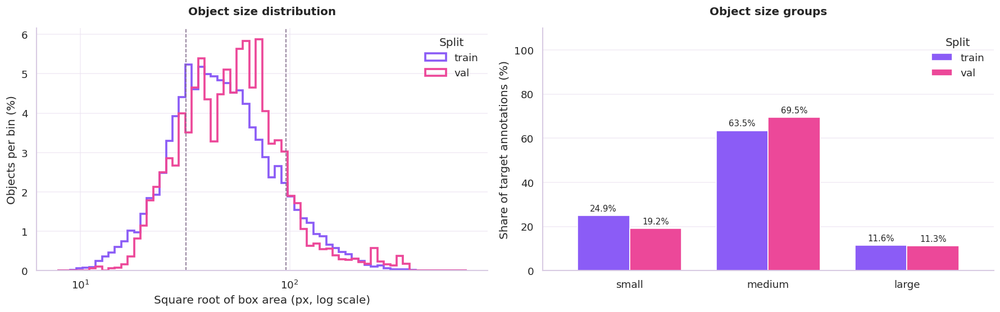

In [10]:
objects_df["sqrt_area"] = np.sqrt(objects_df["box_area"])
objects_df["relative_area_pct"] = objects_df["relative_area"] * 100

SIZE_ORDER = ["small", "medium", "large"]

objects_df["size_group"] = pd.Categorical(
    np.select(
        [
            objects_df["box_area"] < 32**2,
            objects_df["box_area"] < 96**2,
        ],
        ["small", "medium"],
        default="large",
    ),
    categories=SIZE_ORDER,
    ordered=True,
)

size_summary = (
    objects_df.groupby("split", observed=True)
    .agg(
        median_width_px=("box_width", "median"),
        median_height_px=("box_height", "median"),
        median_sqrt_area_px=("sqrt_area", "median"),
        median_relative_area_pct=("relative_area_pct", "median"),
    )
)

display(size_summary.round(3))

size_counts = pd.crosstab(
    objects_df["size_group"],
    objects_df["split"],
).reindex(
    index=SIZE_ORDER,
    columns=["train", "val"],
    fill_value=0,
)

size_shares = size_counts.div(size_counts.sum(axis=0), axis=1) * 100
display(size_shares.round(2).rename_axis("size_group"))

fig, axes = plt.subplots(1, 2, figsize=(15, 4.8))

area_bins = np.geomspace(
    objects_df["sqrt_area"].min(),
    objects_df["sqrt_area"].max(),
    65,
)

for split, color in SPLIT_COLORS.items():
    values = objects_df.loc[
        objects_df["split"].eq(split), "sqrt_area"
    ].to_numpy()

    axes[0].hist(
        values,
        bins=area_bins,
        weights=np.full(values.size, 100.0 / values.size),
        histtype="step",
        linewidth=2.2,
        color=color,
        label=split,
    )

for boundary in (32, 96):
    axes[0].axvline(
        boundary, color="#806B8A", linestyle="--", linewidth=1
    )

axes[0].set_xscale("log")
axes[0].set_xlabel("Square root of box area (px, log scale)")
axes[0].set_ylabel("Objects per bin (%)")
axes[0].set_title("Object size distribution")
axes[0].legend(title="Split", frameon=False)

size_shares.plot.bar(
    ax=axes[1],
    color=[SPLIT_COLORS["train"], SPLIT_COLORS["val"]],
    width=0.75,
)

for container in axes[1].containers:
    axes[1].bar_label(container, fmt="%.1f%%", padding=3, fontsize=9)

axes[1].set_xlabel("")
axes[1].set_ylabel("Share of target annotations (%)")
axes[1].set_title("Object size groups")
axes[1].set_ylim(0, 110)
axes[1].tick_params(axis="x", rotation=0)
axes[1].grid(axis="x", visible=False)
axes[1].legend(title="Split", frameon=False)

plt.tight_layout()
plt.show()

### Object Sizes: Findings

We find that medium-sized boxes dominate in original-image pixels:
63.50% in training and 69.53% in validation. Small boxes account
for 24.91% and 19.20%, respectively.

We observe larger typical object sizes in validation: the median
square root of box area is 52.39 px, compared with 45.83 px in
training. The median relative box area is only 0.100% of the
image in training and 0.116% in validation.

These measurements describe the original images. We next estimate
how resizing changes object dimensions before selecting input
resolutions for our experiments.

### Effect of Input Resolution

We simulate aspect-ratio-preserving resizing into square inputs
of 640, 960, and 1280 pixels. We scale each image's longest side
to the target size; padding does not change box dimensions.

We compare the median box size and the percentage of boxes whose
shorter side becomes smaller than 8 or 16 pixels. We use these
thresholds as descriptive indicators, not strict detection limits.
This simulation does not represent every detector's resizing policy.

,split,input_size,median_sqrt_area_px,median_short_side_px,short_side_lt_8_pct,short_side_lt_16_pct
0,train,640,15.20,12.10,22.04,69.27
1,train,960,22.79,18.15,5.86,40.55
2,train,1280,30.39,24.20,1.71,22.04
3,val,640,16.32,12.62,19.01,68.17
4,val,960,24.48,18.93,6.66,37.30
5,val,1280,32.64,25.24,1.88,19.01


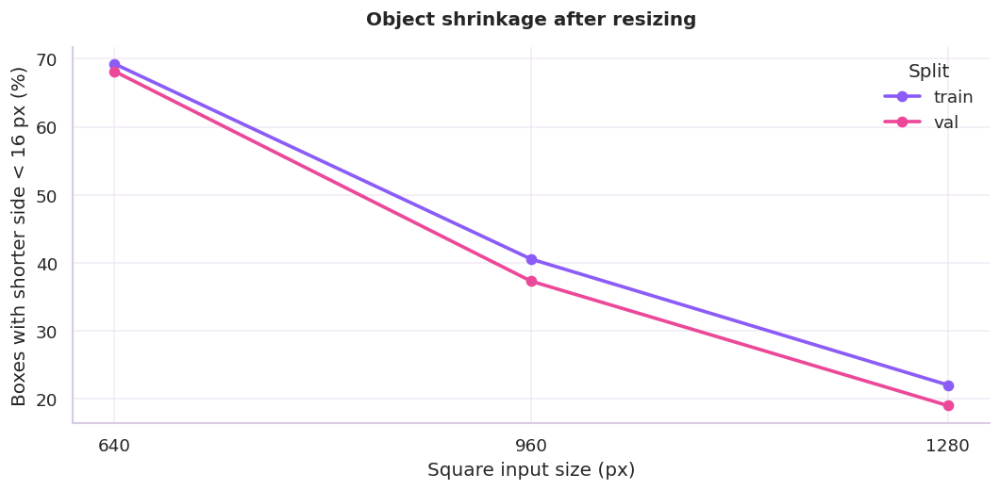

In [11]:
INPUT_SIZES = [640, 960, 1280]

resize_rows = []

for split in ("train", "val"):
    split_objects = objects_df.loc[objects_df["split"].eq(split)]

    longest_side = split_objects[["width", "height"]].max(axis=1).to_numpy()
    shortest_box_side = (
        split_objects[["box_width", "box_height"]].min(axis=1).to_numpy()
    )
    sqrt_area = split_objects["sqrt_area"].to_numpy()

    for input_size in INPUT_SIZES:
        scale = input_size / longest_side
        resized_short_side = shortest_box_side * scale

        resize_rows.append({
            "split": split,
            "input_size": input_size,
            "median_sqrt_area_px": np.median(sqrt_area * scale),
            "median_short_side_px": np.median(resized_short_side),
            "short_side_lt_8_pct": 100 * (resized_short_side < 8).mean(),
            "short_side_lt_16_pct": 100 * (resized_short_side < 16).mean(),
        })

resize_summary = pd.DataFrame(resize_rows)

display(
    resize_summary.style.format({
        "input_size": "{:.0f}",
        "median_sqrt_area_px": "{:.2f}",
        "median_short_side_px": "{:.2f}",
        "short_side_lt_8_pct": "{:.2f}",
        "short_side_lt_16_pct": "{:.2f}",
    })
)

fig, ax = plt.subplots(figsize=(9, 4.5))

for split, color in SPLIT_COLORS.items():
    subset = resize_summary.loc[resize_summary["split"].eq(split)]

    ax.plot(
        subset["input_size"],
        subset["short_side_lt_16_pct"],
        marker="o",
        linewidth=2.2,
        color=color,
        label=split,
    )

ax.set_xticks(INPUT_SIZES)
ax.set_xlabel("Square input size (px)")
ax.set_ylabel("Boxes with shorter side < 16 px (%)")
ax.set_title("Object shrinkage after resizing")
ax.legend(title="Split", frameon=False)

plt.tight_layout()
plt.show()

### Input Resolution: Findings

We observe substantial object shrinkage at a 640-pixel input:
69.27% of training boxes and 68.17% of validation boxes have
a shorter side below 16 pixels.

At 960 pixels, these proportions decrease to 40.55% and 37.30%.
At 1280 pixels, they decrease further to 22.04% and 19.01%.

These results motivate experiments with higher input resolutions.
However, we have not yet measured their effect on detection accuracy.
We will compare validation AP, inference speed, and GPU memory use
before selecting the final resolution.

### Resizing Used by Our Baseline Detectors

Our square-input simulation illustrates how resolution affects object
sizes, but it differs from the preprocessing used by our Faster R-CNN
and RetinaNet baselines.

For these baselines, we resize images while preserving aspect ratio,
targeting a shorter side of 640 pixels and limiting the longer side
to 1152 pixels. The nominal scale is

$$
s = \min\left(
\frac{640}{\min(H, W)},
\frac{1152}{\max(H, W)}
\right).
$$

We estimate the resulting object dimensions below. These are analytical
estimates; integer rounding in the image transform can introduce small
differences. Padding for batching does not change box dimensions.

,median_scale,median_width_px,median_height_px,median_sqrt_area_px,median_short_side_px,short_side_lt_8_pct,short_side_lt_16_pct
split,,,,,,,
train,0.6,26.29,28.09,27.02,21.51,2.99,28.12
val,0.6,25.10,33.02,29.01,22.43,3.13,24.68


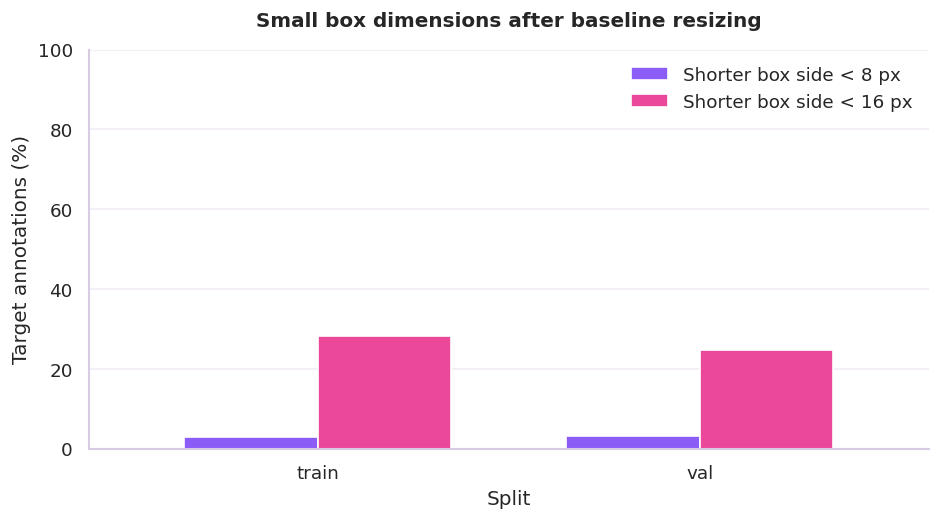

In [12]:
BASELINE_MIN_SIZE = 640
BASELINE_MAX_SIZE = 1152

baseline_resize = objects_df[
    ["split", "width", "height", "box_width", "box_height"]
].copy()

short_image_side = baseline_resize[
    ["width", "height"]
].min(axis=1)

long_image_side = baseline_resize[
    ["width", "height"]
].max(axis=1)

baseline_resize["scale"] = np.minimum(
    BASELINE_MIN_SIZE / short_image_side,
    BASELINE_MAX_SIZE / long_image_side,
)

baseline_resize["resized_width"] = (
    baseline_resize["box_width"] * baseline_resize["scale"]
)
baseline_resize["resized_height"] = (
    baseline_resize["box_height"] * baseline_resize["scale"]
)

baseline_resize["short_box_side"] = baseline_resize[
    ["resized_width", "resized_height"]
].min(axis=1)

baseline_resize["sqrt_area"] = np.sqrt(
    baseline_resize["resized_width"]
    * baseline_resize["resized_height"]
)

baseline_resize["short_side_lt_8"] = (
    baseline_resize["short_box_side"] < 8
)
baseline_resize["short_side_lt_16"] = (
    baseline_resize["short_box_side"] < 16
)

baseline_resize_summary = (
    baseline_resize.groupby("split", observed=True)
    .agg(
        median_scale=("scale", "median"),
        median_width_px=("resized_width", "median"),
        median_height_px=("resized_height", "median"),
        median_sqrt_area_px=("sqrt_area", "median"),
        median_short_side_px=("short_box_side", "median"),
        short_side_lt_8_pct=("short_side_lt_8", "mean"),
        short_side_lt_16_pct=("short_side_lt_16", "mean"),
    )
    .reindex(["train", "val"])
)

percentage_columns = [
    "short_side_lt_8_pct",
    "short_side_lt_16_pct",
]

baseline_resize_summary[percentage_columns] *= 100

display(baseline_resize_summary.round(2))

fig, ax = plt.subplots(figsize=(8, 4.5))

baseline_resize_summary[percentage_columns].rename(
    columns={
        "short_side_lt_8_pct": "Shorter box side < 8 px",
        "short_side_lt_16_pct": "Shorter box side < 16 px",
    }
).plot.bar(
    ax=ax,
    color=["#8B5CF6", "#EC4899"],
    rot=0,
    width=0.7,
)

ax.set_title("Small box dimensions after baseline resizing")
ax.set_xlabel("Split")
ax.set_ylabel("Target annotations (%)")
ax.set_ylim(0, 100)
ax.legend(frameon=False)
ax.grid(axis="x", visible=False)

plt.tight_layout()
plt.show()

### Baseline Resizing: Findings

Under our baseline resizing policy, 28.12% of training boxes and 24.68%
of validation boxes have a shorter side below 16 pixels. Approximately
3% fall below 8 pixels in both splits.

The median shorter box side is 21.51 pixels in training and 22.43 pixels
in validation. Small box dimensions therefore remain relevant even
though this policy preserves more detail than our earlier 640-pixel
square-input simulation.

These findings motivate testing smaller anchors and higher input
resolutions. They do not establish which configuration performs best;
we will assess that using validation AP, runtime, and memory use.

### Baseline Preprocessing Protocol

We use the following preprocessing for our initial Faster R-CNN and
RetinaNet experiments.

| Component | Setting |
|---|---|
| Image representation | RGB, float32 tensor in [0, 1] |
| Resizing | Shorter side 640 px, longer side at most 1152 px; aspect ratio preserved |
| Normalization mean | (0.485, 0.456, 0.406) |
| Normalization standard deviation | (0.229, 0.224, 0.225) |
| Training augmentation | None in the initial baselines |
| Frame sampling | All frames; sampling step 1 |
| Random seed | 42 |
| Validation design | Fixed folds grouped by video sequence |
| Faster R-CNN target labels | 1–8; 0 reserved for background |
| RetinaNet target labels | 0–7; background represented by negative classification targets |

We apply resizing and normalization inside the detector transform,
avoiding duplicate preprocessing in the dataset loader.

We retain all frames in the initial experiments to preserve the available
training annotations. Adjacent frames remain correlated; sequence-based
splits prevent the same video from appearing in both training and
validation within a fold.

We separate ignored regions from target boxes. During training, we
exclude background anchors or proposals with intersection over candidate
area of at least 0.5 with an ignored region. We preserve positive
matches. Ignored and non-target regions are not assigned an additional
target class.

We start without augmentation to establish a controlled baseline.
Any later changes to preprocessing or augmentation will be documented
as separate experiments.

### Scene Density Across Frames and Clips

We examine the distribution of target-object counts per frame,
including frames without target objects. We compare typical
and crowded scenes using medians, upper quantiles, and maxima.

We also summarize individual clips to identify differences
that may be hidden by split-level averages.

,count,mean,std,min,median,90%,95%,99%,max
split,,,,,,,,,
train,24201.0,45.68,31.56,0.0,43.0,92.0,118.0,142.00,180.0
val,2846.0,40.10,26.85,8.0,37.0,81.0,103.0,112.55,116.0


Clips with the highest mean object counts:


,split,video,frames,mean_objects,median_objects,max_objects
14,train,uav0000138_00000_v,213,142.96,150.0,156
13,train,uav0000126_00001_v,412,132.22,130.0,166
12,train,uav0000124_00944_v,398,124.57,129.0,134
5,train,uav0000072_04488_v,85,110.38,108.0,124
18,train,uav0000150_02310_v,348,108.89,102.0,174
58,val,uav0000137_00458_v,233,103.38,105.0,116
33,train,uav0000279_00001_v,547,95.35,108.0,126
51,train,uav0000357_00920_v,691,91.89,93.0,104
7,train,uav0000072_06432_v,97,89.95,85.0,113
53,train,uav0000361_02323_v,219,85.80,86.0,94


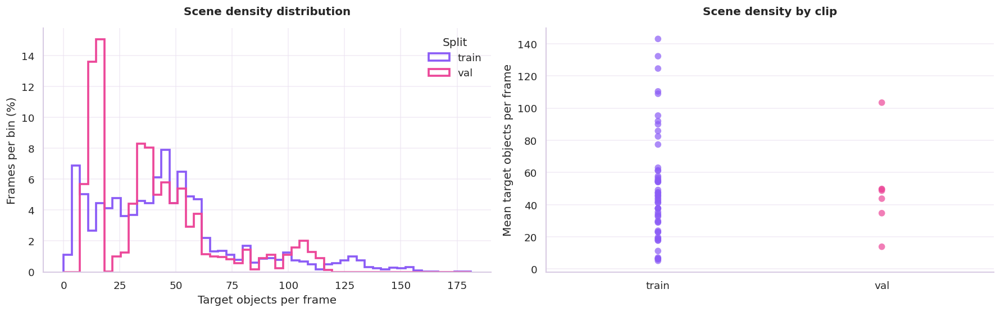

In [13]:
density_summary = (
    frames_df.groupby("split", observed=True)["n_objects"]
    .describe(percentiles=[0.5, 0.9, 0.95, 0.99])
    .rename(columns={"50%": "median"})
)

display(density_summary.round(2))

clip_summary = (
    frames_df.groupby(["split", "video"], observed=True)
    .agg(
        frames=("image_id", "size"),
        mean_objects=("n_objects", "mean"),
        median_objects=("n_objects", "median"),
        max_objects=("n_objects", "max"),
    )
    .reset_index()
)

print("Clips with the highest mean object counts:")
display(
    clip_summary.sort_values("mean_objects", ascending=False)
    .head(10)
    .round(2)
)

fig, axes = plt.subplots(1, 2, figsize=(15, 4.8))

# Shared bins; each split is normalized separately.
count_bins = np.linspace(
    0, frames_df["n_objects"].max() + 1, 51
)

for split, color in SPLIT_COLORS.items():
    counts = frames_df.loc[
        frames_df["split"].eq(split), "n_objects"
    ].to_numpy()

    axes[0].hist(
        counts,
        bins=count_bins,
        weights=np.full(counts.size, 100.0 / counts.size),
        histtype="step",
        linewidth=2.2,
        color=color,
        label=split,
    )

axes[0].set_xlabel("Target objects per frame")
axes[0].set_ylabel("Frames per bin (%)")
axes[0].set_title("Scene density distribution")
axes[0].legend(title="Split", frameon=False)

sns.stripplot(
    data=clip_summary,
    x="split",
    y="mean_objects",
    order=["train", "val"],
    hue="split",
    palette=SPLIT_COLORS,
    jitter=False,
    dodge=False,
    size=7,
    alpha=0.7,
    ax=axes[1],
)

if axes[1].get_legend() is not None:
    axes[1].get_legend().remove()

axes[1].set_xlabel("")
axes[1].set_ylabel("Mean target objects per frame")
axes[1].set_title("Scene density by clip")
axes[1].grid(axis="x", visible=False)

plt.tight_layout()
plt.show()

### Scene Density: Findings

We observe median object counts of 43 per training frame and
37 per validation frame. The maximum counts reach 180 and 116,
respectively. The 95th percentiles are 118 objects in training
and 103 in validation.

We also find substantial variation across clips. The densest
training clip contains an average of 142.96 target objects per frame,
while the densest validation clip averages 103.38.

These findings motivate checking proposal counts, query counts,
and final detection limits separately. A limit of 100 final
detections can restrict recall on crowded frames. We will keep
evaluation settings consistent across model comparisons.

### Class Coverage Across Clips

We examine how many clips contain each target class and visualize
class proportions within individual clips.

This helps us distinguish frequent appearances across adjacent
frames from coverage across different video sequences.

split,train_clips_with_class,val_clips_with_class
class_name,,
person,55,7
bicycle,41,5
car,49,6
van,46,6
truck,39,5
tricycle,39,5
bus,24,1
motor,50,6


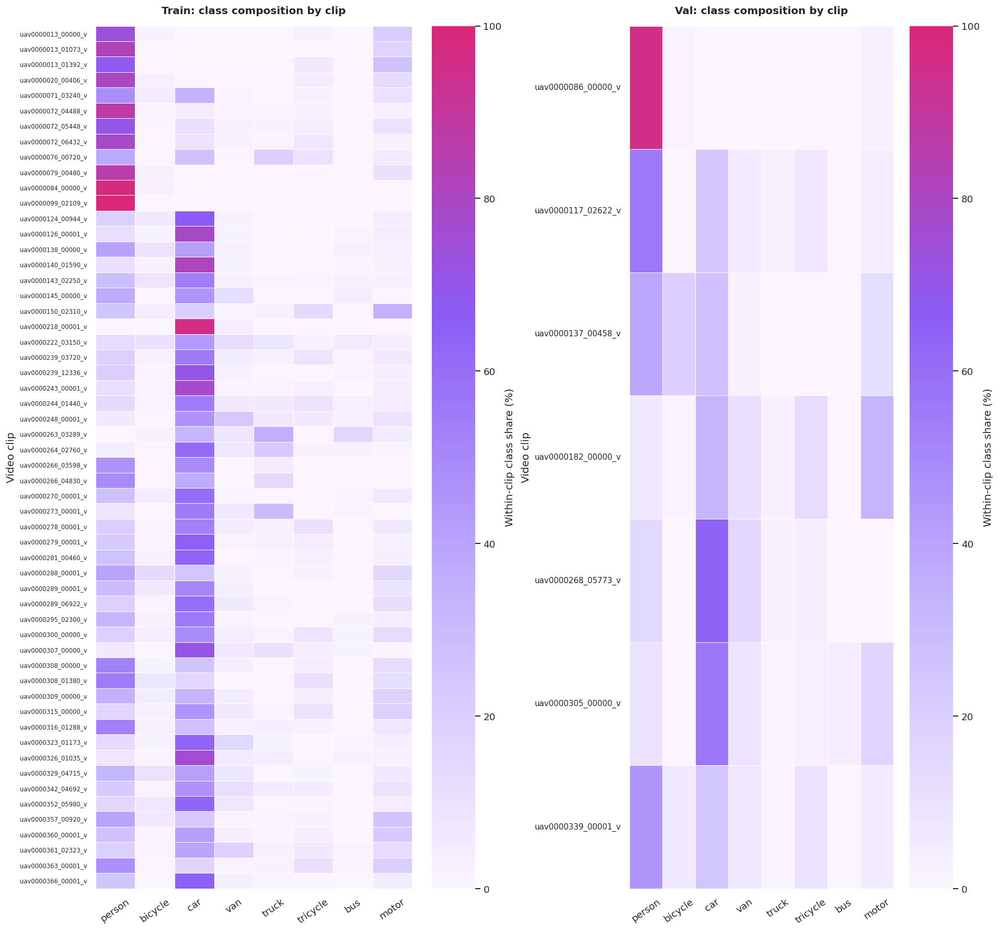

In [14]:
clip_class_counts = (
    objects_df.groupby(
        ["split", "video", "class_name"],
        observed=True,
    )
    .size()
    .unstack("class_name", fill_value=0)
    .reindex(columns=CLASS_NAMES, fill_value=0)
)

all_clips = pd.MultiIndex.from_frame(
    frames_df[["split", "video"]].drop_duplicates()
)
clip_class_counts = clip_class_counts.reindex(all_clips, fill_value=0)

clip_coverage = (
    clip_class_counts.gt(0)
    .groupby(level="split", observed=True)
    .sum()
    .T
    .reindex(index=CLASS_NAMES, columns=["train", "val"])
)

display(
    clip_coverage.rename(columns={
        "train": "train_clips_with_class",
        "val": "val_clips_with_class",
    })
)

clip_class_shares = (
    clip_class_counts
    .div(clip_class_counts.sum(axis=1).replace(0, np.nan), axis=0)
    .mul(100)
    .fillna(0)
)

fig, axes = plt.subplots(
    1, 2,
    figsize=(16, 15),
    gridspec_kw={"width_ratios": [1.2, 1]},
)

for ax, split in zip(axes, ["train", "val"]):
    shares = clip_class_shares.xs(split, level="split").sort_index()

    sns.heatmap(
        shares,
        ax=ax,
        cmap=PURPLE_PINK_CMAP,
        vmin=0,
        vmax=100,
        yticklabels=True,
        linewidths=0.3,
        cbar_kws={"label": "Within-clip class share (%)"},
    )

    ax.set_title(f"{split.capitalize()}: class composition by clip")
    ax.set_xlabel("")
    ax.set_ylabel("Video clip")
    ax.tick_params(axis="x", rotation=35)
    ax.tick_params(axis="y", labelsize=7 if split == "train" else 9)

plt.tight_layout()
plt.show()

### Class Coverage Across Clips: Findings

We find all eight target classes in both splits, but their coverage
across clips differs substantially.

People appear in 55 of 56 training clips and all 7 validation clips.
Buses appear in 24 training clips but only one validation clip.
Thus, all 264 validation bus annotations come from a single sequence,
which limits how broadly we can interpret validation AP for this class.

We also observe distinct class compositions across clips, with some
sequences dominated by people and others by cars. These differences
support sequence-level cross-validation and per-class evaluation.

### Visual Inspection of Annotations

We inspect representative and crowded frames from both splits.
We draw target boxes using class-specific colors and mark ignored
regions with dashed outlines.

We select frames near the median object count and frames with the
highest object count. We use this targeted inspection to check
coordinate alignment and understand challenging scenes.

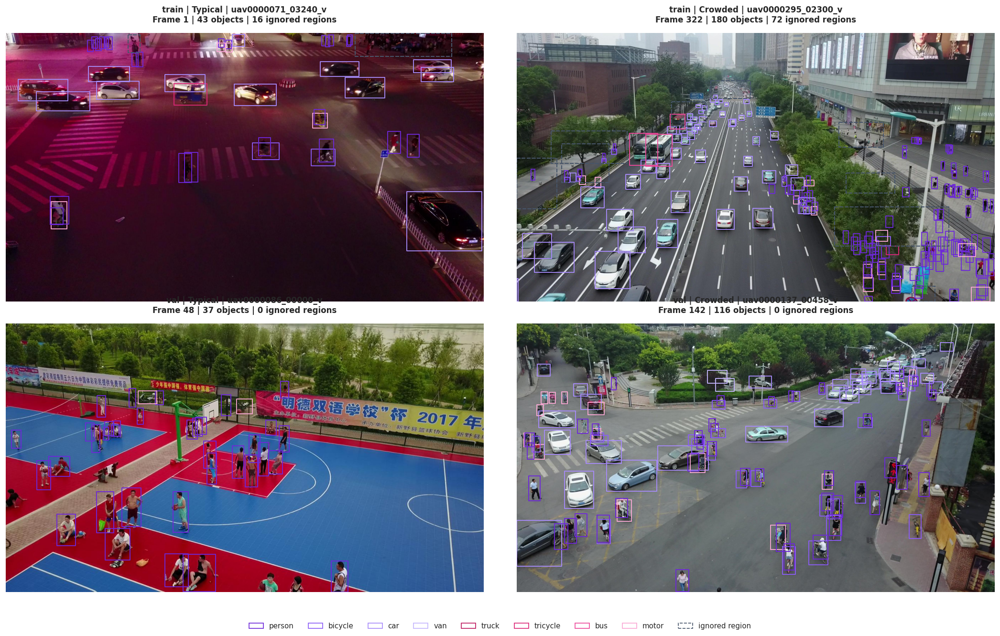

In [15]:
from PIL import Image
from matplotlib.collections import PatchCollection
from matplotlib.patches import Rectangle, Patch

CLASS_COLOR_MAP = dict(zip(CLASS_NAMES, CLASS_COLORS))
IGNORE_COLOR = "#475569"

selected_frames = []

for split in ("train", "val"):
    subset = frames_df.loc[frames_df["split"].eq(split)]

    median_index = (
        subset["n_objects"] - subset["n_objects"].median()
    ).abs().idxmin()
    dense_index = subset["n_objects"].idxmax()

    selected_frames.extend([
        ("Typical", frames_df.loc[median_index]),
        ("Crowded", frames_df.loc[dense_index]),
    ])

selected_ids = {
    split: {
        int(row["image_id"])
        for _, row in selected_frames
        if row["split"] == split
    }
    for split in ("train", "val")
}

selected_annotations = {
    (split, image_id): []
    for split, image_ids in selected_ids.items()
    for image_id in image_ids
}

for split, coco in annotations.items():
    for ann in coco["annotations"]:
        if ann["image_id"] in selected_ids[split]:
            selected_annotations[(split, ann["image_id"])].append(ann)

fig, axes = plt.subplots(2, 2, figsize=(18, 11))

for ax, (scene_type, row) in zip(axes.flat, selected_frames):
    split = row["split"]
    image_path = DATA_ROOT / split / row["file_name"]

    with Image.open(image_path) as image:
        ax.imshow(image.convert("RGB"))

    target_rectangles, target_colors = [], []
    ignored_rectangles = []

    for ann in selected_annotations[(split, int(row["image_id"]))]:
        x, y, width, height = ann["bbox"]
        rectangle = Rectangle((x, y), width, height)

        if ann.get("iscrowd", 0) == 1:
            ignored_rectangles.append(rectangle)
        else:
            class_name = CLASS_NAMES[ann["category_id"] - 1]
            target_rectangles.append(rectangle)
            target_colors.append(CLASS_COLOR_MAP[class_name])

    ax.add_collection(PatchCollection(
        target_rectangles,
        facecolor="none",
        edgecolor=target_colors,
        linewidth=1.1,
    ))

    ax.add_collection(PatchCollection(
        ignored_rectangles,
        facecolor="none",
        edgecolor=IGNORE_COLOR,
        linewidth=1.2,
        linestyle="--",
    ))

    ax.set_title(
        f"{split} | {scene_type} | {row['video']}\n"
        f"Frame {row['frame_id']} | "
        f"{row['n_objects']} objects | {row['n_ignored']} ignored regions",
        fontsize=10,
    )
    ax.axis("off")

legend_handles = [
    Patch(facecolor="none", edgecolor=CLASS_COLOR_MAP[name], label=name)
    for name in CLASS_NAMES
]
legend_handles.append(
    Patch(
        facecolor="none",
        edgecolor=IGNORE_COLOR,
        linestyle="--",
        label="ignored region",
    )
)

fig.legend(
    handles=legend_handles,
    loc="lower center",
    ncol=9,
    frameon=False,
    fontsize=9,
)

plt.tight_layout(rect=(0, 0.05, 1, 1))
plt.show()

### Verification of Converted and Resized Targets

We convert COCO xywh boxes to the xyxy tensors expected by our detectors.
We verify that converting back recovers the original coordinates.

We then apply the baseline TorchVision resizing and normalization on CPU.
We resize ignored regions using the same coordinate transformation as
target boxes. For display, we reverse normalization and remove batch
padding.

We compare original and transformed images to inspect box alignment.
Target labels are 1–8 for Faster R-CNN and 0–7 for RetinaNet.

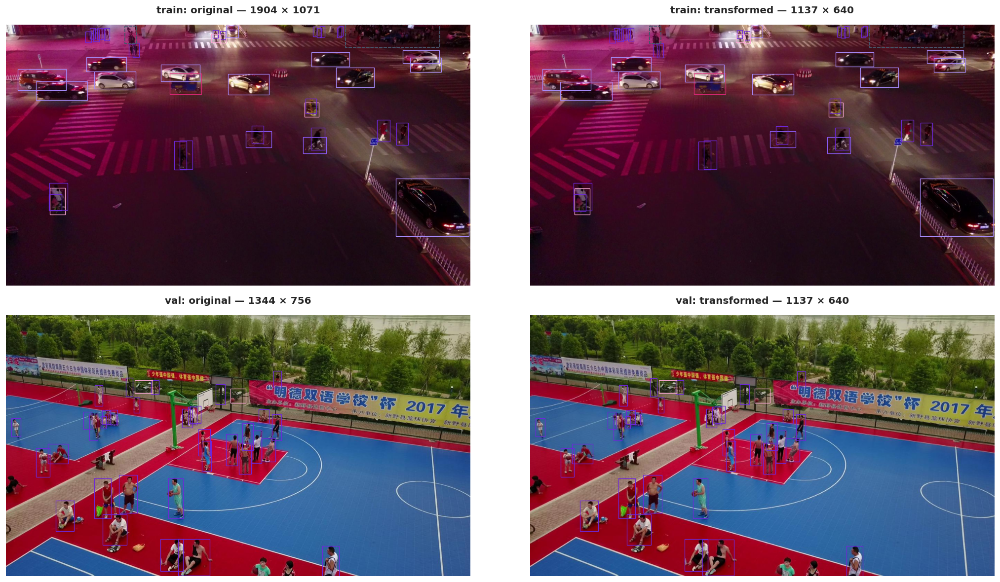

,split,image_id,targets,ignored_regions,resized_width,resized_height
0,train,947,43,16,1137,640
1,val,48,37,0,1137,640


Box conversion, label mapping, and resize checks passed.


In [17]:
import torch

from torchvision.models.detection.transform import (
    GeneralizedRCNNTransform,
    resize_boxes,
)
from torchvision.transforms.functional import pil_to_tensor


class EDAIgnoreAwareTransform(GeneralizedRCNNTransform):
    def resize(self, image, target=None):
        original_size = image.shape[-2:]
        target = target.copy() if target is not None else None
        ignored = target.get("ignore_boxes") if target is not None else None

        image, target = super().resize(image, target)

        if ignored is not None:
            target["ignore_boxes"] = resize_boxes(
                ignored,
                original_size,
                image.shape[-2:],
            )

        return image, target


eda_transform = EDAIgnoreAwareTransform(
    min_size=640,
    max_size=1152,
    image_mean=[0.485, 0.456, 0.406],
    image_std=[0.229, 0.224, 0.225],
).eval()


def convert_eda_targets(records):
    ignored_mask = [
        bool(record.get("iscrowd", 0))
        or bool(record.get("ignore", 0))
        for record in records
    ]

    targets = [
        record for record, ignored in zip(records, ignored_mask)
        if not ignored
    ]
    ignored = [
        record for record, is_ignored in zip(records, ignored_mask)
        if is_ignored
    ]

    def convert_boxes(items):
        xywh = torch.tensor(
            [item["bbox"] for item in items],
            dtype=torch.float32,
        ).reshape(-1, 4)

        xyxy = xywh.clone()
        xyxy[:, 2:] += xyxy[:, :2]

        recovered = xyxy.clone()
        recovered[:, 2:] -= recovered[:, :2]
        torch.testing.assert_close(recovered, xywh)

        return xyxy

    labels = torch.tensor(
        [record["category_id"] for record in targets],
        dtype=torch.int64,
    )
    assert ((labels >= 1) & (labels <= 8)).all()

    retina_labels = labels - 1
    assert ((retina_labels >= 0) & (retina_labels <= 7)).all()

    return {
        "boxes": convert_boxes(targets),
        "labels": labels,
        "ignore_boxes": convert_boxes(ignored),
    }


def draw_converted_boxes(ax, image, target):
    ax.imshow(image)

    for box, label in zip(
        target["boxes"].numpy(),
        target["labels"].numpy(),
    ):
        x1, y1, x2, y2 = box
        ax.add_patch(Rectangle(
            (x1, y1), x2 - x1, y2 - y1,
            fill=False,
            edgecolor=CLASS_COLORS[int(label) - 1],
            linewidth=0.8,
        ))

    for box in target["ignore_boxes"].numpy():
        x1, y1, x2, y2 = box
        ax.add_patch(Rectangle(
            (x1, y1), x2 - x1, y2 - y1,
            fill=False,
            edgecolor=IGNORE_COLOR,
            linestyle="--",
            linewidth=1,
        ))

    ax.axis("off")


# Reuse the previously selected typical frame from each split.
inspection_frames = [
    row for scene_type, row in selected_frames
    if scene_type == "Typical"
]

fig, axes = plt.subplots(2, 2, figsize=(18, 10))
conversion_rows = []

with torch.no_grad():
    for row_index, row in enumerate(inspection_frames):
        split = row["split"]
        image_id = int(row["image_id"])

        with Image.open(
            DATA_ROOT / split / row["file_name"]
        ) as source:
            image = pil_to_tensor(
                source.convert("RGB")
            ).float() / 255

        target = convert_eda_targets(
            selected_annotations[(split, image_id)]
        )

        batch, transformed_targets = eda_transform(
            [image], [target]
        )

        resized_height, resized_width = batch.image_sizes[0]
        transformed = transformed_targets[0]

        mean = image.new_tensor(
            eda_transform.image_mean
        ).view(3, 1, 1)
        std = image.new_tensor(
            eda_transform.image_std
        ).view(3, 1, 1)

        restored_image = (
            batch.tensors[0, :, :resized_height, :resized_width]
            * std + mean
        ).clamp(0, 1)

        for key in ("boxes", "ignore_boxes"):
            expected = resize_boxes(
                target[key],
                image.shape[-2:],
                (resized_height, resized_width),
            )
            torch.testing.assert_close(
                transformed[key], expected
            )

        torch.testing.assert_close(
            transformed["labels"], target["labels"]
        )

        draw_converted_boxes(
            axes[row_index, 0],
            image.permute(1, 2, 0).numpy(),
            target,
        )
        draw_converted_boxes(
            axes[row_index, 1],
            restored_image.permute(1, 2, 0).numpy(),
            transformed,
        )

        axes[row_index, 0].set_title(
            f"{split}: original — "
            f"{image.shape[2]} × {image.shape[1]}"
        )
        axes[row_index, 1].set_title(
            f"{split}: transformed — "
            f"{resized_width} × {resized_height}"
        )

        conversion_rows.append({
            "split": split,
            "image_id": image_id,
            "targets": len(target["boxes"]),
            "ignored_regions": len(target["ignore_boxes"]),
            "resized_width": resized_width,
            "resized_height": resized_height,
        })

plt.tight_layout()
plt.show()

display(pd.DataFrame(conversion_rows))
print("Box conversion, label mapping, and resize checks passed.")

### Conversion Verification: Findings

The coordinate round-trip and resizing checks passed for the inspected
training and validation frames. Target counts and labels were preserved,
and ignored regions were transformed alongside target boxes.

We observe no obvious systematic box misalignment in these examples.
This inspection supports the conversion checks but does not replace
dataset-wide coordinate validation.

### Box Shapes and Sizes Across Classes and Clips

We compare box dimensions and aspect ratios across classes.
We define aspect ratio as width divided by height: values below
one indicate tall boxes, while values above one indicate wide boxes.

We also compare median object sizes and small-object proportions
across clips. We use training statistics to motivate candidate
anchor settings and validation statistics to describe split differences.

,median_width_px,median_height_px,median_sqrt_area_px,median_aspect_ratio,small_pct
class_name,,,,,
person,25.0,50.0,35.779999,0.50,39.49
bicycle,43.0,43.0,41.410000,0.95,24.41
car,67.0,48.0,57.009998,1.25,16.32
van,55.0,46.0,49.849998,1.11,21.40
truck,79.0,68.0,73.459999,1.08,9.39
tricycle,59.0,51.0,54.849998,1.06,21.03
bus,121.0,103.0,113.449997,1.03,4.14
motor,38.0,43.0,40.209999,0.80,30.37


Clips with the highest small-object proportions:


,split,video,median_sqrt_area_px,small_pct
25,train,uav0000248_00001_v,29.980000,73.09
22,train,uav0000239_12336_v,24.490000,65.18
27,train,uav0000264_02760_v,31.000000,54.47
32,train,uav0000278_00001_v,31.500000,51.07
59,val,uav0000182_00000_v,32.450001,49.16
21,train,uav0000239_03720_v,33.320000,47.83
33,train,uav0000279_00001_v,33.360001,47.57
17,train,uav0000145_00000_v,38.259998,46.20
23,train,uav0000243_00001_v,35.209999,44.37
10,train,uav0000084_00000_v,38.880001,39.07


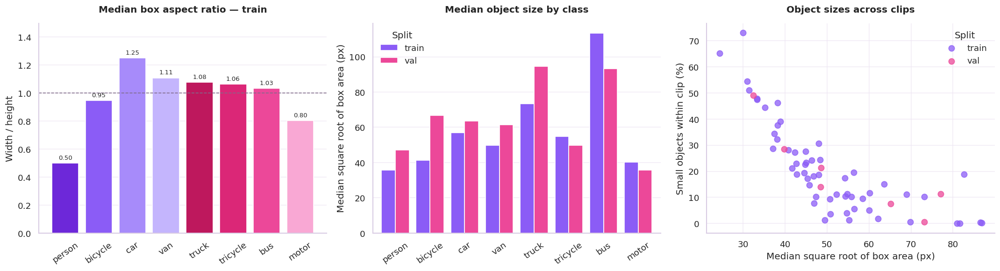

In [16]:
objects_df["aspect_ratio"] = (
    objects_df["box_width"] / objects_df["box_height"]
)
objects_df["is_small"] = objects_df["box_area"].lt(32**2)

class_geometry = (
    objects_df.loc[objects_df["split"].eq("train")]
    .groupby("class_name", observed=True)
    .agg(
        median_width_px=("box_width", "median"),
        median_height_px=("box_height", "median"),
        median_sqrt_area_px=("sqrt_area", "median"),
        median_aspect_ratio=("aspect_ratio", "median"),
        small_fraction=("is_small", "mean"),
    )
    .reindex(CLASS_NAMES)
)

class_geometry["small_pct"] = class_geometry.pop("small_fraction") * 100
display(class_geometry.round(2))

clip_geometry = (
    objects_df.groupby(["split", "video"], observed=True)
    .agg(
        median_sqrt_area_px=("sqrt_area", "median"),
        small_fraction=("is_small", "mean"),
    )
    .reset_index()
)

clip_geometry["small_pct"] = clip_geometry.pop("small_fraction") * 100

print("Clips with the highest small-object proportions:")
display(
    clip_geometry.sort_values("small_pct", ascending=False)
    .head(10)
    .round(2)
)

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

bars = axes[0].bar(
    CLASS_NAMES,
    class_geometry["median_aspect_ratio"],
    color=CLASS_COLORS,
)
axes[0].bar_label(bars, fmt="%.2f", padding=3, fontsize=8)
axes[0].axhline(1, color="#806B8A", linestyle="--", linewidth=1)
axes[0].set_title("Median box aspect ratio — train")
axes[0].set_ylabel("Width / height")
axes[0].tick_params(axis="x", rotation=35)
axes[0].margins(y=0.2)
axes[0].grid(axis="x", visible=False)

class_median_sizes = (
    objects_df.groupby(["class_name", "split"], observed=True)["sqrt_area"]
    .median()
    .unstack("split")
    .reindex(index=CLASS_NAMES, columns=["train", "val"])
)

class_median_sizes.plot.bar(
    ax=axes[1],
    color=[SPLIT_COLORS["train"], SPLIT_COLORS["val"]],
    width=0.8,
)
axes[1].set_title("Median object size by class")
axes[1].set_xlabel("")
axes[1].set_ylabel("Median square root of box area (px)")
axes[1].tick_params(axis="x", rotation=35)
axes[1].grid(axis="x", visible=False)
axes[1].legend(title="Split", frameon=False)

for split, color in SPLIT_COLORS.items():
    subset = clip_geometry.loc[clip_geometry["split"].eq(split)]
    axes[2].scatter(
        subset["median_sqrt_area_px"],
        subset["small_pct"],
        color=color,
        s=55,
        alpha=0.75,
        label=split,
    )

axes[2].set_title("Object sizes across clips")
axes[2].set_xlabel("Median square root of box area (px)")
axes[2].set_ylabel("Small objects within clip (%)")
axes[2].legend(title="Split", frameon=False)

plt.tight_layout()
plt.show()

### Fixed Sequence-Based Cross-Validation

We reuse the saved three-fold manifest used in our detector experiments.
We verify that every training frame has exactly one assignment and
that all frames from the same video belong to one fold.

For each fold, we check that fitting and held-out video sets are
disjoint. The supplied validation split remains separate from these
training-data folds.

In [25]:
import kagglehub

folds_directory = Path(
    kagglehub.dataset_download("darynashevchuk12/train-folds")
)

fold_paths = sorted(folds_directory.rglob("train_folds.csv"))
assert fold_paths, f"Fold manifest not found in {folds_directory}"

saved_folds = pd.read_csv(fold_paths[0])

assert {"image_id", "fold"}.issubset(saved_folds.columns)
print("Fold manifest:", fold_paths[0])

Fold manifest: /kaggle/input/datasets/darynashevchuk12/train-folds/train_folds.csv


In [24]:
training_frames = frames_df.loc[
    frames_df["split"].eq("train")
].copy()

assert saved_folds["image_id"].is_unique
assert training_frames["image_id"].is_unique
assert set(saved_folds["image_id"]) == set(
    training_frames["image_id"]
)
assert set(saved_folds["fold"]) == {0, 1, 2}

fold_frames = training_frames.merge(
    saved_folds[["image_id", "fold"]],
    on="image_id",
    validate="one_to_one",
)

assert (
    fold_frames.groupby("video", observed=True)["fold"]
    .nunique()
    .eq(1)
    .all()
), "Some training videos belong to multiple folds."

train_videos = set(training_frames["video"])
val_videos = set(
    frames_df.loc[frames_df["split"].eq("val"), "video"]
)

assert train_videos.isdisjoint(val_videos)

fold_checks = []

for fold_id in range(3):
    fit = fold_frames.loc[
        fold_frames["fold"].ne(fold_id)
    ]
    holdout = fold_frames.loc[
        fold_frames["fold"].eq(fold_id)
    ]

    shared_videos = set(fit["video"]) & set(holdout["video"])
    assert not shared_videos

    fold_checks.append({
        "fold": fold_id,
        "fit_clips": fit["video"].nunique(),
        "fit_frames": len(fit),
        "holdout_clips": holdout["video"].nunique(),
        "holdout_frames": len(holdout),
        "shared_videos": len(shared_videos),
    })

display(pd.DataFrame(fold_checks).set_index("fold"))

print("Manifest:", fold_paths[0])
print("Shared train/val videos:", len(train_videos & val_videos))
print("Fixed sequence-fold checks passed.")

,fit_clips,fit_frames,holdout_clips,holdout_frames,shared_videos
fold,,,,,
0,37,16121,19,8080,0
1,37,16119,19,8082,0
2,38,16162,18,8039,0


Manifest: /kaggle/input/datasets/darynashevchuk12/train-folds/train_folds.csv
Shared train/val videos: 0
Fixed sequence-fold checks passed.


### EDA Summary and Implications

We verified the annotation structure and found no overlapping videos
between the supplied training and validation splits. All target boxes
passed the coordinate checks. Conversion and resizing checks passed
for the inspected examples, with no obvious systematic box misalignment.

We observed substantial class imbalance and variation across sequences.
Cars account for 45.71% of training annotations, while people account
for 44.08% of validation annotations. All validation bus annotations
come from one sequence, limiting the generality of its per-class AP.

Object sizes and shapes vary across classes and clips. Under our actual
baseline resizing policy, 28.12% of training boxes and 24.68% of validation
boxes have a shorter side below 16 pixels. These findings motivate
experiments with smaller anchors and higher input resolutions.

Scene density reaches 180 target objects per training frame and 116
per validation frame. We therefore examine proposal counts and final
detection limits, and will consider scene density when configuring
query-based detectors.

We reuse three fixed sequence-based folds. Their held-out portions
contain 8,080, 8,082, and 8,039 frames, with no video shared between
fitting and held-out portions. We retain the supplied validation split
for final evaluation after configuration selection.

Our initial baselines use all frames, no augmentation, seed 42, and
documented resizing and normalization. We handle ignored regions
explicitly while preserving positive matches.

We will assess the choices motivated by this EDA through controlled
experiments, reporting per-class and size-specific AP alongside
runtime and memory use.